In [15]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D3/'

In [16]:
df_cosine = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_scm.csv')
df_scm['similarity'] = 'scm'

In [17]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with KiralyMSMApproximateClustering,3186,0.20,cosine,63.64,63.70,63.67,702,401,2787,400,cosine,[title],1024,0,1,salted_qgrams,,4
1,Clustering with KiralyMSMApproximateClustering,3186,0.10,cosine,63.64,63.70,63.67,702,401,2787,400,cosine,[title],1024,0,1,salted_qgrams,,4
2,Clustering with KiralyMSMApproximateClustering,3191,0.30,cosine,63.93,63.70,63.82,702,396,2787,400,cosine,[title],1024,0,1,salted_qgrams,,4
3,Clustering with KiralyMSMApproximateClustering,3216,0.40,cosine,64.31,62.61,63.45,690,383,2775,412,cosine,[title],1024,0,1,salted_qgrams,,4
4,Clustering with KiralyMSMApproximateClustering,3283,0.50,cosine,64.71,59.07,61.76,651,355,2736,451,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Clustering with KiralyMSMApproximateClustering,988,0.55,scm,57.19,51.27,54.07,565,423,2650,537,scm,[title],1024,0,32,salted_qgrams,,4
2428,Clustering with KiralyMSMApproximateClustering,973,0.65,scm,59.92,52.90,56.19,583,390,2668,519,scm,[title],1024,0,32,salted_qgrams,,4
2429,Clustering with KiralyMSMApproximateClustering,796,0.75,scm,63.32,45.74,53.11,504,292,2589,598,scm,[title],1024,0,32,salted_qgrams,,4
2430,Clustering with KiralyMSMApproximateClustering,476,0.85,scm,61.34,26.50,37.01,292,184,2377,810,scm,[title],1024,0,32,salted_qgrams,,4


In [18]:
result['attributes'].value_counts()

attributes
[title]    2432
Name: count, dtype: int64

In [19]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [20]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [21]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [22]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [23]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [24]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
2,Clustering with KiralyMSMApproximateClustering,3191,0.30,cosine,63.93,63.70,63.82,702,396,2787,400,cosine,[title],1024,0,1,salted_qgrams,,4
899,Clustering with KiralyMSMApproximateClustering,1064,0.35,dice,63.53,61.34,62.42,676,388,2761,426,dice,[title],1024,0,1,salted_qgrams,,4
1505,Clustering with KiralyMSMApproximateClustering,1079,0.15,jaccard,63.11,61.80,62.45,681,398,2766,421,jaccard,[title],1024,0,1,salted_qgrams,,4
1824,Clustering with KiralyMSMApproximateClustering,3425,0.80,scm,60.19,47.19,52.90,520,344,2605,582,scm,[title],1024,0,1,salted_qgrams,,4
301,Clustering with KiralyMSMApproximateClustering,1093,0.35,cosine,64.14,63.61,63.87,701,392,2786,401,cosine,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2418,Clustering with KiralyMSMApproximateClustering,978,0.65,scm,60.02,53.27,56.44,587,391,2672,515,scm,[title],1024,0,31,salted_qgrams,,4
283,Clustering with KiralyMSMApproximateClustering,3240,0.30,cosine,64.06,60.98,62.48,672,377,2757,430,cosine,[title],1024,0,32,salted_qgrams,,4
894,Clustering with KiralyMSMApproximateClustering,3221,0.20,dice,63.11,61.16,62.12,674,394,2759,428,dice,[title],1024,0,32,salted_qgrams,,4
1503,Clustering with KiralyMSMApproximateClustering,3221,0.10,jaccard,63.11,61.16,62.12,674,394,2759,428,jaccard,[title],1024,0,32,salted_qgrams,,4


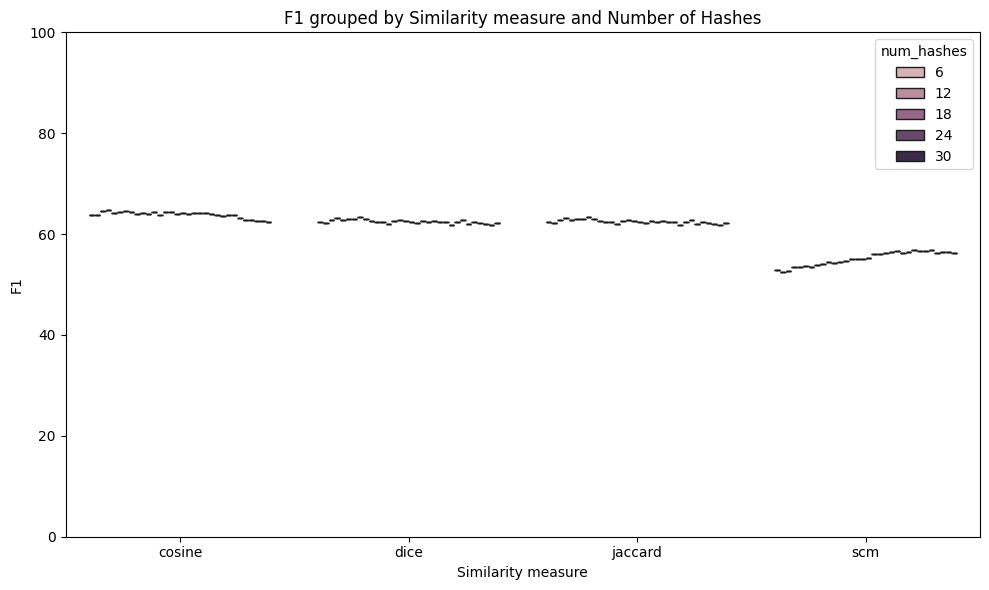

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [26]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,63.93
1,dice,1,Precision %,63.53
2,jaccard,1,Precision %,63.11
3,scm,1,Precision %,60.19
4,cosine,2,Precision %,64.14
...,...,...,...,...
379,scm,31,F1 %,56.44
380,cosine,32,F1 %,62.48
381,dice,32,F1 %,62.12
382,jaccard,32,F1 %,62.12


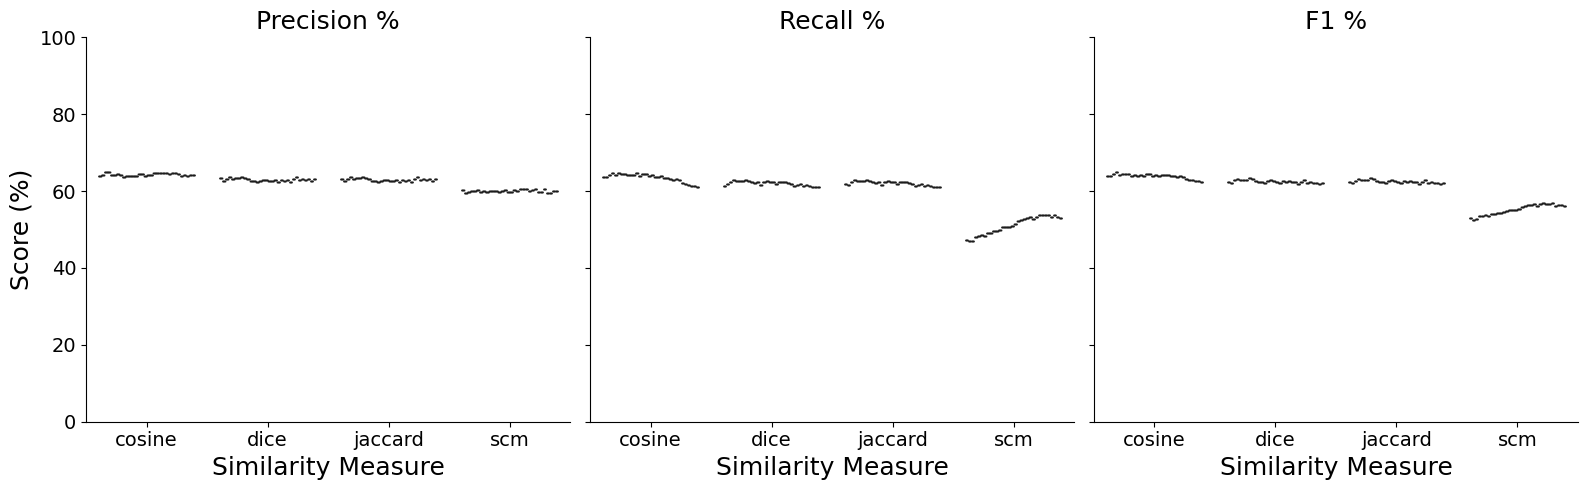

In [27]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

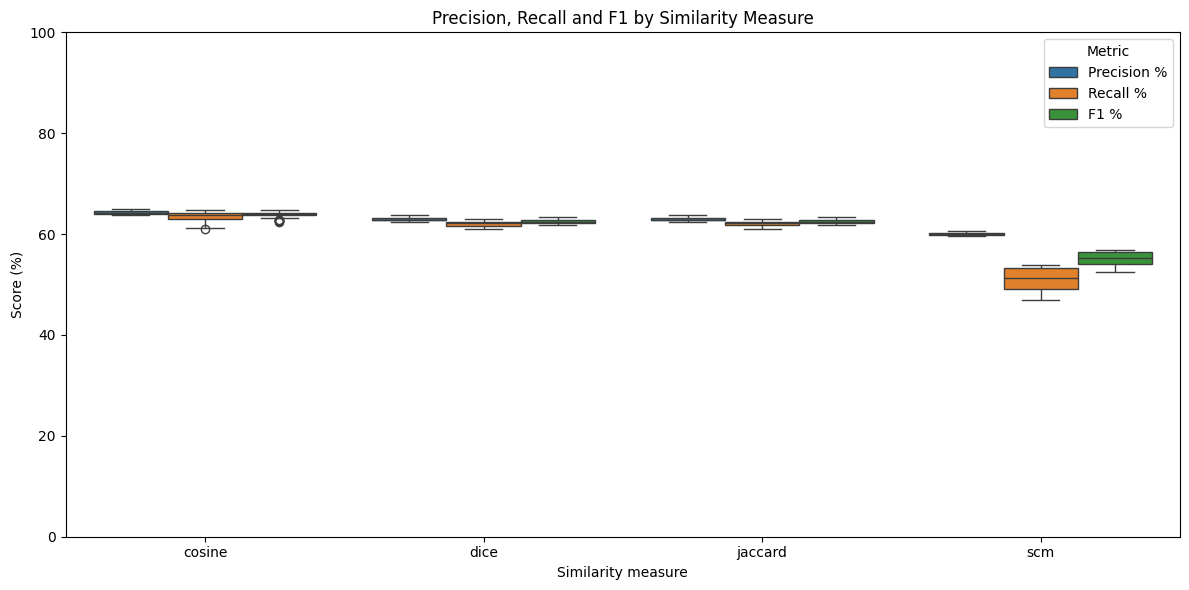

In [28]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()